# 🛒 Customer Segmentation & Customer Behavior Prediction

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_excel("dataset/Online Retail.xlsx")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df.shape

(541909, 8)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [5]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [6]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [7]:
df.nunique()

InvoiceNo      25900
StockCode       4070
Description     4223
Quantity         722
InvoiceDate    23260
UnitPrice       1630
CustomerID      4372
Country           38
dtype: int64

In [8]:
df.sample(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
506982,579165,22619,SET OF 6 SOLDIER SKITTLES,4,2011-11-28 14:01:00,3.75,13389.0,United Kingdom
174908,551858,51014A,"FEATHER PEN,HOT PINK",36,2011-05-04 15:33:00,0.85,18041.0,United Kingdom
217181,555918,22381,TOY TIDY PINK POLKADOT,9,2011-06-07 16:21:00,2.10,16098.0,United Kingdom
490494,578059,23355,HOT WATER BOTTLE KEEP CALM,8,2011-11-22 15:15:00,4.95,13940.0,United Kingdom
257404,559526,23052,RECYCLED ACAPULCO MAT TURQUOISE,1,2011-07-10 11:19:00,8.25,15756.0,United Kingdom
405867,571716,84598,BOYS ALPHABET IRON ON PATCHES,8,2011-10-18 17:05:00,0.42,NaN,United Kingdom
27880,538566,85032B,BLOSSOM IMAGES GIFT WRAP SET,1,2010-12-13 11:21:00,4.21,NaN,United Kingdom
536133,581219,22703,PINK CAT BOWL,4,2011-12-08 09:28:00,1.63,NaN,United Kingdom
324630,565410,21756,BATH BUILDING BLOCK WORD,3,2011-09-04 11:17:00,5.95,14691.0,United Kingdom
175894,551994,23146,TRIPLE HOOK ANTIQUE IVORY ROSE,4,2011-05-05 15:42:00,3.29,12868.0,United Kingdom


## Understand cancellations
The UCI documentation says that an InvoiceNo beginning with C indicates a cancellation.

In [9]:
df[df["InvoiceNo"].astype(str).str.startswith("C")].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [10]:
cancelled = df["InvoiceNo"].astype(str).str.startswith("C")

cancelled.sum()

np.int64(9288)

## Create Total Amount

In [11]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]

In [12]:
df[["Quantity", "UnitPrice", "TotalAmount"]].head()


,Quantity,UnitPrice,TotalAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


## Cleaning The data

In [13]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

Removing Customers without ID, Invalid Quantities & Invalid prices

In [14]:
df = df.dropna(subset=["CustomerID"])

In [15]:
df = df[df["Quantity"] > 0]

In [16]:
df = df[df["UnitPrice"] > 0]

In [17]:
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

In [18]:
df = df.reset_index(drop=True)

In [19]:
df.shape

(397884, 9)

In [20]:
df["TotalAmount"].sum()


np.float64(8911407.904)

In [21]:
df["CustomerID"].nunique()

4338

In [22]:
df["InvoiceNo"].nunique()

18532

In [23]:
df["Country"].value_counts().head(10)

Country
United Kingdom    354321
Germany             9040
France              8341
EIRE                7236
Spain               2484
Netherlands         2359
Belgium             2031
Switzerland         1841
Portugal            1462
Australia           1182
Name: count, dtype: int64

In [24]:
df.groupby("Description")["Quantity"].sum().sort_values(
    ascending=False
).head(10)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54415
JUMBO BAG RED RETROSPOT               46181
WHITE HANGING HEART T-LIGHT HOLDER    36725
ASSORTED COLOUR BIRD ORNAMENT         35362
PACK OF 72 RETROSPOT CAKE CASES       33693
POPCORN HOLDER                        30931
RABBIT NIGHT LIGHT                    27202
MINI PAINT SET VINTAGE                26076
Name: Quantity, dtype: int64

In [25]:
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

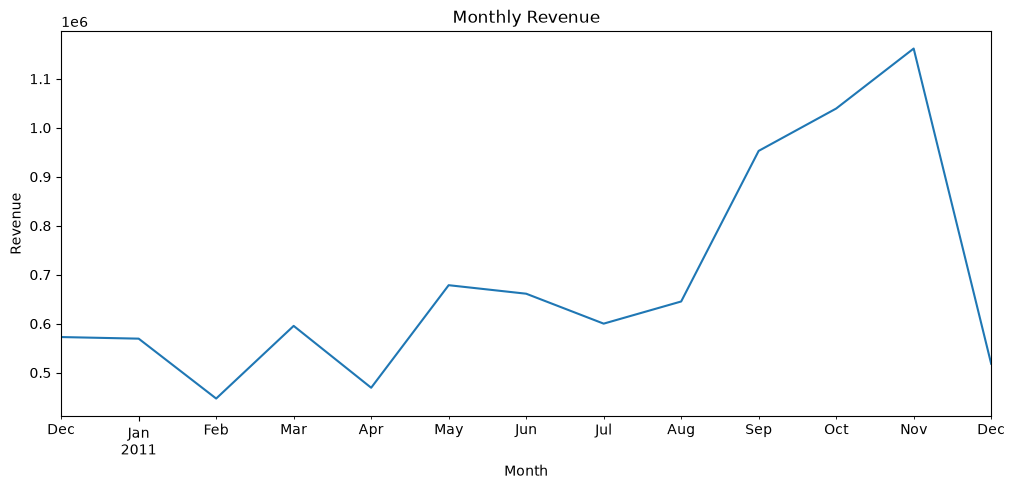

In [26]:
monthly_sales = df.groupby("YearMonth")["TotalAmount"].sum()

monthly_sales.plot(figsize=(12, 5))

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.show()

## RFM

In [27]:
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

reference_date

Timestamp('2011-12-10 12:50:00')

Below cell working: differnce batye ga ky between customer last purchase and your last transaction date. store it in invoiceDate, then save unique items that a customer buy in InvoiceNo, and save total amount he spend in TotalAmount.

In [28]:
rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (reference_date - x.max()).days,
    "InvoiceNo": "nunique",
    "TotalAmount": "sum"
})

Renaming Columns

In [29]:
rfm.columns = [
    "Recency",
    "Frequency",
    "Monetary"
]

In [30]:
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [31]:
rfm.describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460
std,100.014169,7.697998,8989.230441
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,307.415000
50%,51.000000,2.000000,674.485000
75%,142.000000,5.000000,1661.740000
max,374.000000,209.000000,280206.020000


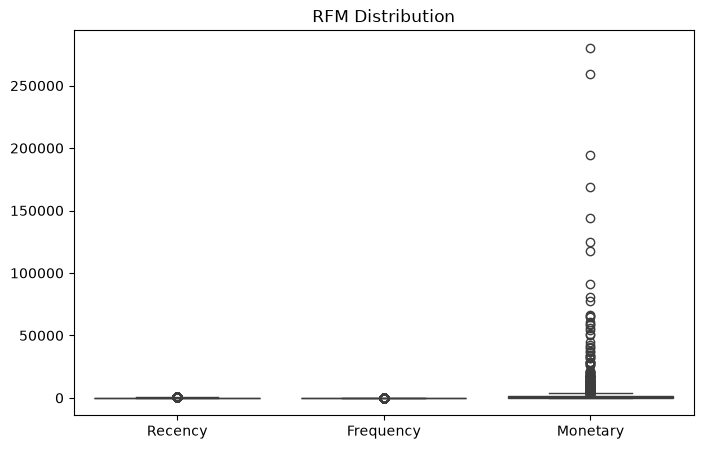

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=rfm)

plt.title("RFM Distribution")

plt.show()

In [33]:
rfm_log = np.log1p(rfm)

## Feature Scaling


would give Monetary much more influence simply because its numbers are larger.

In [34]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

## Find The Best Number Of Clusters

In [35]:
from sklearn.cluster import KMeans

inertia = []

K = range(2, 11)

for k in K:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(rfm_scaled)

    inertia.append(model.inertia_)

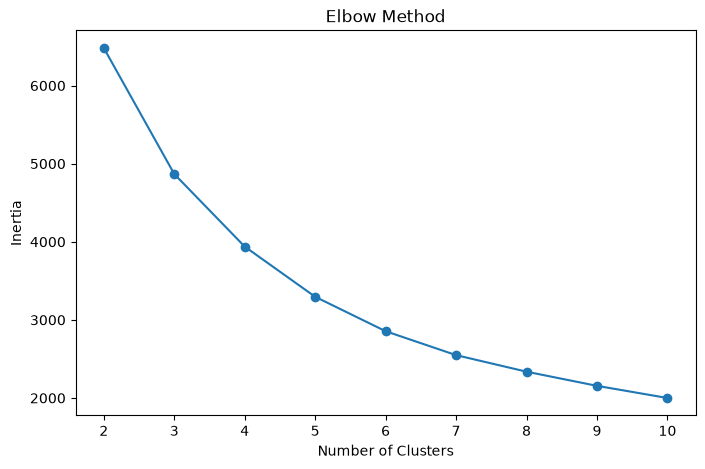

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(K, inertia, marker="o")

plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

## K-Means

In [37]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

In [38]:
rfm.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,2
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,2
12349.0,19,1,1757.55,0
12350.0,310,1,334.40,3


## Understand each cluster

In [39]:
cluster_summary = rfm.groupby("Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

cluster_summary

,Recency,Frequency,Monetary
Cluster,,,
0,18.12,2.15,551.82
1,12.13,13.71,8074.27
2,71.08,4.08,1802.83
3,182.50,1.32,343.45


## PCA

In [40]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

rfm_pca = pca.fit_transform(rfm_scaled)

In [41]:
pca_df = pd.DataFrame(
    rfm_pca,
    columns=["PC1", "PC2"],
    index=rfm.index
)

pca_df["Cluster"] = rfm["Cluster"].values

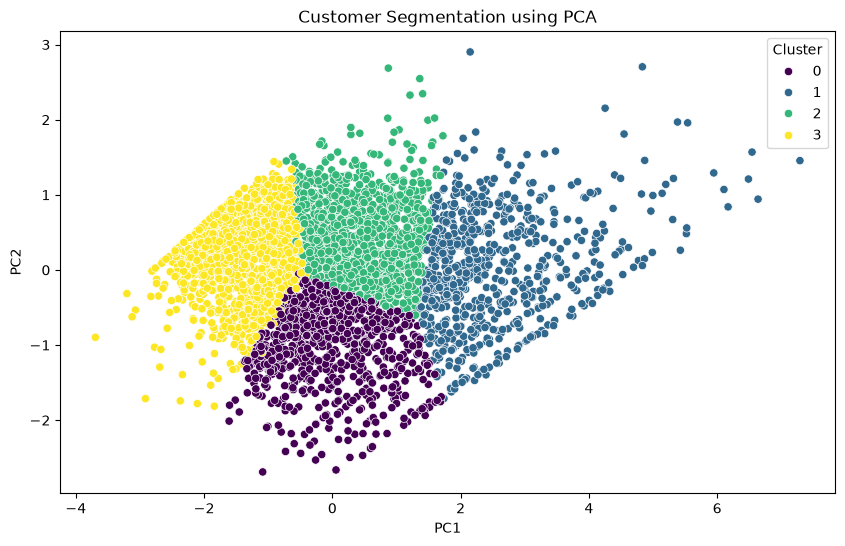

In [42]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="viridis"
)

plt.title("Customer Segmentation using PCA")

plt.show()

### Our final system will have TWO ML components:
* Model 1 — Unsupervised

RFM
 ↓
K-Means
 ↓
Customer Segments

* Model 2 — Supervised

We'll define a future customer behavior target, for example:
Will this customer make another purchase
within the next N days?

In [43]:
df.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalAmount', 'YearMonth'],
      dtype='str')

## Set the prediction cutoff
We'll reserve the last 90 days of available transaction history to create our target.

In [44]:
max_date = df["InvoiceDate"].max()

cutoff_date = max_date - pd.Timedelta(days=90)

print("Last transaction:", max_date)
print("Prediction cutoff:", cutoff_date)

Last transaction: 2011-12-09 12:50:00
Prediction cutoff: 2011-09-10 12:50:00


## Split past and future transactions

In [45]:
history = df[df["InvoiceDate"] < cutoff_date].copy()

future = df[
    (df["InvoiceDate"] >= cutoff_date) &
    (df["InvoiceDate"] <= max_date)
].copy()

In [46]:
print("Historical transactions:", history.shape)
print("Future transactions:", future.shape)

Historical transactions: (236358, 10)
Future transactions: (161526, 10)


## Create The Target Column

In [47]:
future_customers = future["CustomerID"].unique()

In [48]:
reference_date = cutoff_date

customer_features = history.groupby("CustomerID").agg(
    Recency=("InvoiceDate",
             lambda x: (reference_date - x.max()).days),

    Frequency=("InvoiceNo", "nunique"),

    Monetary=("TotalAmount", "sum"),

    TotalQuantity=("Quantity", "sum"),

    UniqueProducts=("StockCode", "nunique")
).reset_index()

In [50]:
customer_features["RepeatPurchase"] = (
    customer_features["CustomerID"]
    .isin(future_customers)
    .astype(int)
)

In [51]:
customer_features.head()

,CustomerID,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,RepeatPurchase
0,12346.0,235,1,77183.60,74215,1,0
1,12347.0,39,5,2790.86,1590,82,1
2,12348.0,158,3,1487.24,2124,22,1
3,12350.0,219,1,334.40,197,17,0
4,12352.0,171,5,1561.81,254,26,1


* 1 the customer purchased during the future 90-day window.
* 0 the customer did not purchase during that window.

## Check the target balance

Before training, see how many customers purchased again.

In [52]:
customer_features["RepeatPurchase"].value_counts()

RepeatPurchase
1    1921
0    1449
Name: count, dtype: int64

In [53]:
customer_features["RepeatPurchase"].value_counts(
    normalize=True
).mul(100).round(2)

RepeatPurchase
1    57.0
0    43.0
Name: proportion, dtype: float64

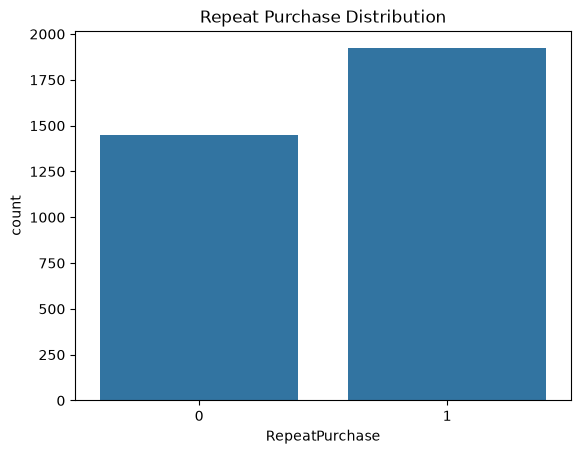

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(
    data=customer_features,
    x="RepeatPurchase"
)

plt.title("Repeat Purchase Distribution")
plt.show()

## Prepare X and y

In [55]:
features = [
    "Recency",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "UniqueProducts"
]

X = customer_features[features]

y = customer_features["RepeatPurchase"]

In [56]:
print("Features:", X.shape)
print("Target:", y.shape)

Features: (3370, 5)
Target: (3370,)


## Split into training and testing data

In [57]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [58]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

In [59]:
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

In [60]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully
Gradient Boosting trained successfully


In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1",
    ascending=False
)

results_df.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.668,0.721,0.680,0.700,0.729,0.796
3,Gradient Boosting,0.660,0.706,0.693,0.699,0.734,0.807
1,Decision Tree,0.659,0.709,0.680,0.694,0.719,0.770
2,Random Forest,0.680,0.771,0.622,0.689,0.736,0.809


Understand these evaluation metrics
- Accuracy: percentage of customers classified correctly.
- Precision: of customers predicted to purchase again, how many actually did?
- Recall: of customers who actually purchased again, how many did the model identify?
- F1-score: balances precision and recall.
- ROC-AUC: measures how well the model ranks positive cases above negative cases.
- PR-AUC: summarizes precision-recall performance and is particularly useful when the target classes are imbalanced.

## Inspect the best model
Once we have the comparison table, select the best candidate by its F1-score.

In [62]:
best_model_name = results_df.iloc[0]["Model"]

best_model = models[best_model_name]

print("Best candidate:", best_model_name)

Best candidate: Logistic Regression


In [63]:
from sklearn.metrics import classification_report

y_pred = best_model.predict(X_test)

print(classification_report(
    y_test,
    y_pred,
    target_names=[
        "No Repeat Purchase",
        "Repeat Purchase"
    ],
    zero_division=0
))

                    precision    recall  f1-score   support

No Repeat Purchase       0.61      0.65      0.63       290
   Repeat Purchase       0.72      0.68      0.70       384

          accuracy                           0.67       674
         macro avg       0.66      0.67      0.66       674
      weighted avg       0.67      0.67      0.67       674



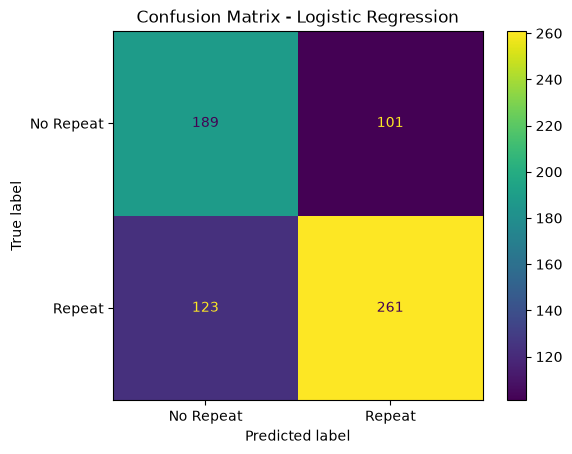

In [64]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=[
        "No Repeat",
        "Repeat"
    ]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.show()

## Hyperparameter tuning
This is where we'll improve the project beyond basic model training.
We'll tune Random Forest using RandomizedSearchCV and cross-validation on the training data. This helps us choose parameters without using the test set to tune the model.

In [65]:
from sklearn.model_selection import RandomizedSearchCV

rf = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid,
    n_iter=15,
    scoring="f1",
    cv=5,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV F1:", search.best_score_)

Best parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 10}
Best CV F1: 0.6761591352971427


In [66]:
best_model = search.best_estimator_

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.58      0.75      0.66       290
           1       0.76      0.60      0.67       384

    accuracy                           0.66       674
   macro avg       0.67      0.67      0.66       674
weighted avg       0.68      0.66      0.66       674



## Understand which features matter
Random Forest can estimate which features contributed most to its decisions.

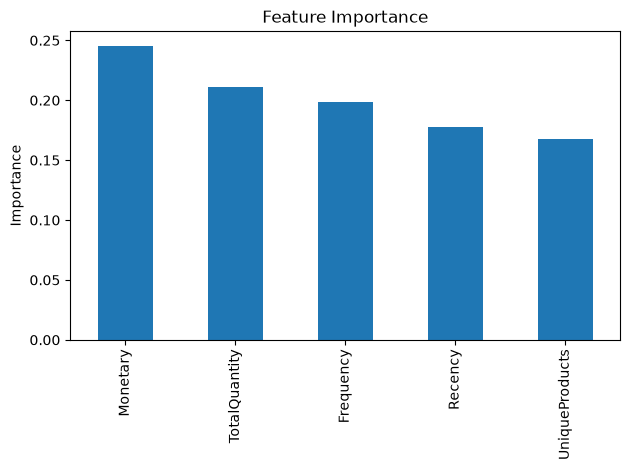

In [67]:
importance = pd.Series(
    best_model.feature_importances_,
    index=features
).sort_values(ascending=False)

importance.plot(
    kind="bar",
    title="Feature Importance"
)

plt.ylabel("Importance")
plt.tight_layout()
plt.show()

## Saving Model

In [68]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    best_model,
    "models/repeat_purchase_model.pkl"
)

joblib.dump(
    features,
    "models/repeat_purchase_features.pkl"
)

['models/repeat_purchase_features.pkl']

In [69]:
model = joblib.load(
    "models/repeat_purchase_model.pkl"
)

In [80]:

from pathlib import Path

models_folder = Path("models")

for file in models_folder.rglob("*"):
    if file.is_file():
        print(file)


models\repeat_purchase_features.pkl
models\repeat_purchase_model.pkl


In [81]:
import joblib
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select customer behavior features
features = [
    "Recency",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "UniqueProducts"
]

X = customer_features[features].copy()

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train K-Means
kmeans = KMeans(
    n_clusters=4,
    init="k-means++",
    random_state=42,
    n_init=10
)

customer_features["Cluster"] = kmeans.fit_predict(X_scaled)

# Save the model and scaler
Path("models").mkdir(exist_ok=True)

joblib.dump(kmeans, "models/kmeans_model.pkl")
joblib.dump(scaler, "models/kmeans_scaler.pkl")

print(customer_features["Cluster"].value_counts().sort_index())
print("K-Means model and scaler saved successfully!")

Cluster
0    1953
1     344
2      15
3    1058
Name: count, dtype: int64
K-Means model and scaler saved successfully!


In [85]:
customer_features.to_csv(
    "customer_features.csv",
    index=False
)